# NII rate-shock model — demo notebook

A small, transparent **Net Interest Income (NII) sensitivity model** for a stylised bank: shock the cash rate, project 24 months of interest income and expense, and see how NII responds.

> **All numbers are illustrative.** The balance sheet, margins and betas in `config/base.yaml` are made up for demonstration and do not represent any real institution.

**How the repo is organised**

| Where | What |
|---|---|
| `config/base.yaml` | Every assumption (balances, margins, betas, repricing, scenarios). Change numbers here, not in code. |
| `src/nii_model/model.py` | The model logic — plain functions, documented and unit-tested. |
| `tests/` | `pytest` checks, run automatically on GitHub for every push. |
| `notebooks/` (this file) | The narrative: run the model, chart the results, explain them. |

Keeping logic in a module and the story in a notebook means the maths is testable and reviewable in pull requests, while the notebook stays readable.

In [1]:
import copy
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Find the repo root so the notebook works wherever it's launched from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "base.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))
import nii_model as nm

pd.options.display.float_format = "{:,.1f}".format

COLOURS = {
    "base": "#52514e",
    "+200bp parallel": "#2a78d6",
    "-200bp parallel": "#eb6834",
    "+200bp ramp (12m)": "#1baf7a",
}
UP, DOWN, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (9, 4.2),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b9b8b3", "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2, "legend.frameon": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": MUTED,
})

## 1. Assumptions

Each balance-sheet line earns or pays `margin + beta × reference rate`, floored where a floor is set.

* **beta** — how much of a cash-rate move is passed on (1.0 for loans; low for transaction accounts).
* **reprice_months** — how long the whole book takes to reprice. A 36-month fixed book only absorbs 1/36 of a shock each month.
* The balance sheet is held **constant** over the horizon, the standard simplifying assumption for an NII-at-risk run.

In [2]:
config = nm.load_config(ROOT / "config" / "base.yaml")
lines = nm.lines_from_config(config)
nm.check_balances(lines)  # raises an error if assets != liabilities + equity

start_rate = config["meta"]["start_cash_rate"]
print(f"{config['meta']['name']} | units: {config['meta']['units']} | starting cash rate {start_rate:.2%}")

bs = nm.balance_sheet_table(lines)
bs.assign(
    margin=bs["margin"].map("{:+.2%}".format),
    beta=bs["beta"].map("{:.2f}".format),
    floor=bs["floor"].map(lambda f: "" if pd.isna(f) else f"{f:.2%}"),
)

Illustrative Bank | units: AUD m | starting cash rate 3.60%

,side,balance,margin,beta,reprice_months,floor
name,,,,,,
Variable home loans,asset,45000,+1.80%,1.00,1,
Fixed home loans,asset,12000,+1.20%,1.00,36,
Business loans,asset,20000,+2.20%,1.00,3,
Liquid assets,asset,18000,+0.20%,1.00,6,
Other assets,asset,5000,+0.00%,0.00,1,
Transaction deposits,liability,22000,+0.00%,0.05,1,0.00%
Savings deposits,liability,25000,-1.00%,0.70,1,0.00%
Term deposits,liability,20000,+0.05%,1.00,9,0.00%
Wholesale funding,liability,25000,+1.10%,1.00,3,


## 2. Rate scenarios

Three shocks against a flat base case: instantaneous ±200bp, and +200bp phased in evenly over 12 months.

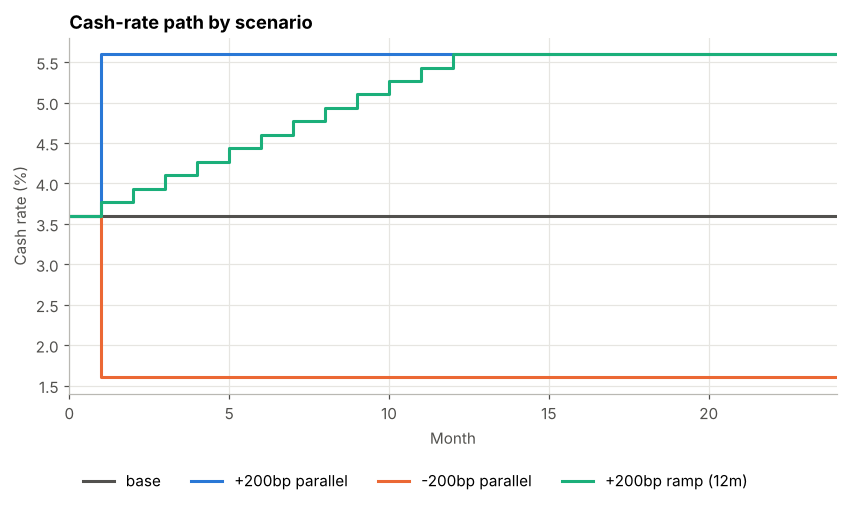

In [3]:
paths = nm.scenario_paths(config)
month0 = pd.DataFrame({name: [start_rate] for name in paths}, index=[0])
plot_paths = pd.concat([month0, paths]) * 100

fig, ax = plt.subplots()
for name in plot_paths:
    ax.plot(plot_paths.index, plot_paths[name], drawstyle="steps-post", color=COLOURS[name], label=name)
ax.set(title="Cash-rate path by scenario", xlabel="Month", ylabel="Cash rate (%)", xlim=(0, 24))
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.18))
plt.show()

## 3. Run the model

In [4]:
results = nm.run_scenarios(config)   # {scenario: monthly interest by line, $m}
summary = nm.nii_summary(results)
summary

,Year 1 NII,Year 2 NII,Year 1 ΔNII,Year 1 ΔNII %,Year 2 ΔNII,Year 2 ΔNII %
base,"2,525.4","2,525.4",0.0,0.0,0.0,0.0
+200bp parallel,"3,023.4","3,036.7",498.0,19.7,511.3,20.2
-200bp parallel,"2,027.4","2,014.1",-498.0,-19.7,-511.3,-20.2
+200bp ramp (12m),"2,801.3","3,017.9",275.9,10.9,492.5,19.5


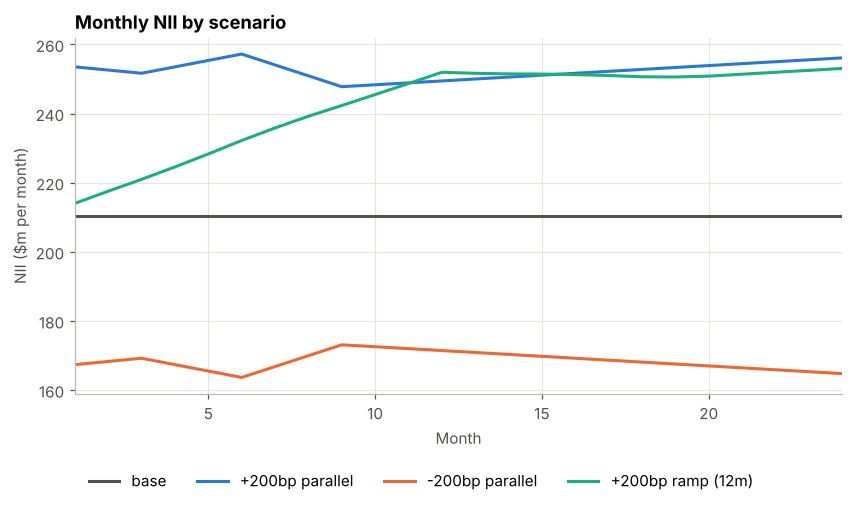

In [5]:
monthly_nii = pd.DataFrame({name: df.sum(axis=1) for name, df in results.items()})

fig, ax = plt.subplots()
for name in monthly_nii:
    ax.plot(monthly_nii.index, monthly_nii[name], color=COLOURS[name], label=name)
ax.set(title="Monthly NII by scenario", xlabel="Month", ylabel="NII ($m per month)", xlim=(1, 24))
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.18))
plt.show()

## 4. What drives the +200bp result?

Breaking the Year 1 change into balance-sheet lines shows where the sensitivity comes from.

Net Year 1 ΔNII: +498m

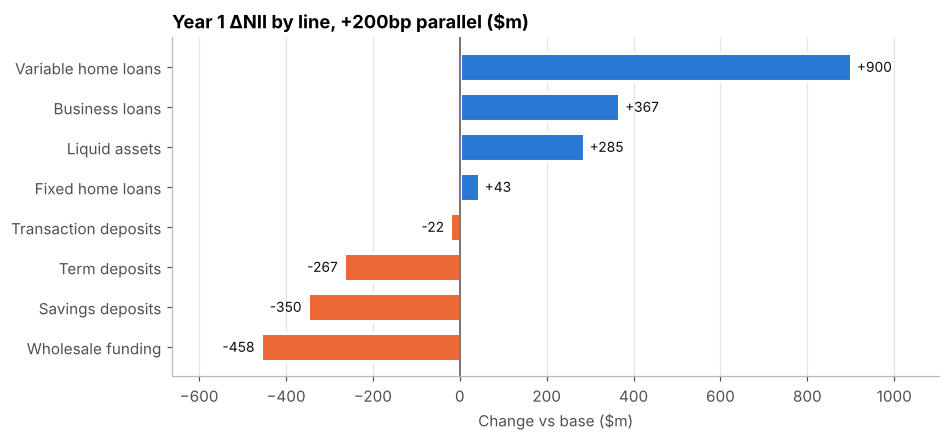

In [6]:
delta = nm.delta_by_line(results, "+200bp parallel")
delta = delta[delta.abs() > 0.05]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(delta.index, delta.values, color=[UP if v > 0 else DOWN for v in delta.values],
        height=0.7, edgecolor="white", linewidth=2)
for y, v in enumerate(delta.values):
    ax.annotate(f"{v:+,.0f}", (v, y), xytext=(4 if v > 0 else -4, 0), textcoords="offset points",
                ha="left" if v > 0 else "right", va="center", fontsize=9, color=INK)
ax.axvline(0, color=MUTED, linewidth=1)
ax.grid(axis="y", visible=False)
ax.margins(x=0.15)
ax.set(title="Year 1 ΔNII by line, +200bp parallel ($m)", xlabel="Change vs base ($m)")
plt.show()

print(f"Net Year 1 ΔNII: {delta.sum():+,.0f}m")

## 5. Is the sensitivity symmetric?

A ladder of instantaneous shocks from −300bp to +300bp. If NII moved linearly with rates, this would be a straight line. The dashed line marks the shock at which savings-deposit rates hit their 0% floor.

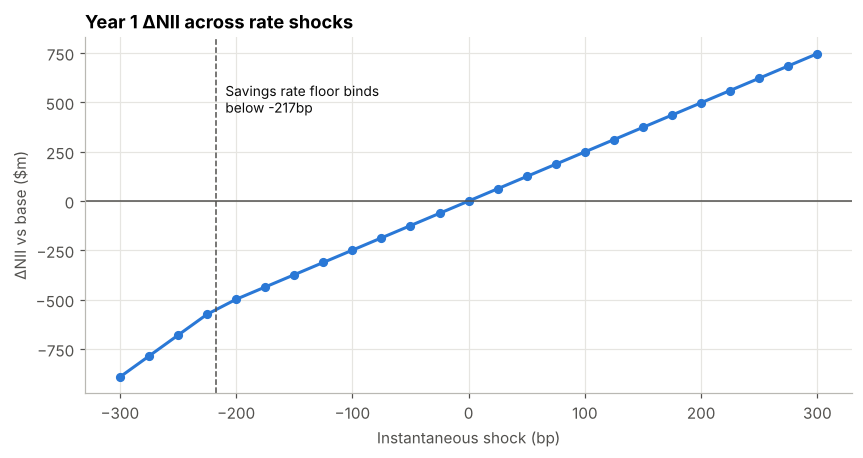

,Year 1 ΔNII ($m)
-300,-892.0
-200,-498.0
-100,-249.0
100,249.0
200,498.0
300,747.0


In [7]:
shocks = list(range(-300, 301, 25))
base_nii = nm.project_nii(lines, nm.rate_path(start_rate, 12), start_rate).to_numpy().sum()
ladder = pd.Series(
    {s: nm.project_nii(lines, nm.rate_path(start_rate, 12, shock_bp=s), start_rate).to_numpy().sum() - base_nii
     for s in shocks},
    name="Year 1 ΔNII ($m)",
)

savings = next(l for l in lines if l.name == "Savings deposits")
floor_bp = ((savings.floor - savings.margin) / savings.beta - start_rate) * 10_000

fig, ax = plt.subplots()
ax.plot(ladder.index, ladder.values, color=UP, marker="o", markersize=5)
ax.axhline(0, color=MUTED, linewidth=1)
ax.axvline(floor_bp, color=MUTED, linewidth=1, linestyle="--")
ax.annotate(f"Savings rate floor binds\nbelow {floor_bp:.0f}bp", (floor_bp, ladder.max() * 0.6),
            xytext=(6, 0), textcoords="offset points", fontsize=9, color=INK)
ax.set(title="Year 1 ΔNII across rate shocks", xlabel="Instantaneous shock (bp)", ylabel="ΔNII vs base ($m)")
plt.show()

ladder.loc[[-300, -200, -100, 100, 200, 300]].to_frame()

## 6. Sensitivity to an assumption: savings deposit beta

Deposit betas are among the most judgemental inputs in any NII model. Re-running with different savings betas shows how much the answer depends on that call.

In [8]:
rows = []
for beta in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    cfg = copy.deepcopy(config)
    for item in cfg["balance_sheet"]:
        if item["name"] == "Savings deposits":
            item["beta"] = beta
    s = nm.nii_summary(nm.run_scenarios(cfg))
    rows.append({
        "Savings beta": f"{beta:.1f}" + (" (current)" if beta == savings.beta else ""),
        "+200bp Year 1 ΔNII": s.loc["+200bp parallel", "Year 1 ΔNII"],
        "-200bp Year 1 ΔNII": s.loc["-200bp parallel", "Year 1 ΔNII"],
    })
pd.DataFrame(rows).set_index("Savings beta")

,+200bp Year 1 ΔNII,-200bp Year 1 ΔNII
Savings beta,,
0.4,648.0,-738.0
0.5,598.0,-648.0
0.6,548.0,-558.0
0.7 (current),498.0,-498.0
0.8,448.0,-448.0
0.9,398.0,-398.0
1.0,348.0,-348.0


## Takeaways

* **The bank is asset-sensitive.** Base NII is about \$2.5bn a year; a +200bp shock adds roughly \$500m (≈20%) in Year 1 and −200bp takes the same amount off. About \$77bn of assets reprice within six months at full pass-through, while \$47bn of transaction and savings deposits pass on only 5% and 70% of a move, and \$8bn of equity is interest-free funding.
* **Timing matters, not just size.** The monthly NII lines wiggle because books reprice on different clocks: wholesale funding catches up within 3 months, liquid assets over 6, term deposits over 9, and fixed home loans are still adding income at month 24. Phasing the shock in over 12 months delivers only about 55% of the instantaneous shock's Year 1 impact, but nearly all of it by Year 2.
* **The downside is steeper than the upside.** Once cuts exceed about 217bp, savings rates hit their 0% floor and the bank can no longer pass cuts through, so −300bp costs about \$890m against +\$750m for +300bp.
* **One judgemental input moves the answer a lot.** Each 0.1 change in the savings beta shifts the ±200bp result by about \$50m, and at low betas the downside grows faster than the upside because the floor binds sooner.
* **No hedging is modelled.** Banks typically hedge much of this sensitivity (for example by investing deposits and capital in a rolling swap portfolio), so treat these as unhedged, illustrative magnitudes.

## Ideas to extend (good practice prompts for an AI coding assistant)

1. **Add a structural hedge** — model a replicating portfolio that invests transaction deposits and equity in a rolling 3- or 5-year swap ladder, and show how it flattens the ladder in section 5.
2. **Non-parallel scenarios** — add short- and long-rate shocks (needs a yield curve rather than one cash rate).
3. **Balance-sheet dynamics** — let deposit balances migrate from transaction to term accounts as rates rise.
4. **EVE alongside NII** — discount cash flows to measure economic value of equity sensitivity.
5. **Load the balance sheet from CSV/Excel** instead of YAML, with validation.

Each is a self-contained change: ask for it on a new branch, check the tests still pass, and open a pull request to review the diff.